In [282]:

import math
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [283]:
# load CIFAR
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# CIFAR-10 mean and std commonly used for normalization
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

use_subset = False
subset_size = 12000

if use_subset:
    train_indices = np.random.choice(len(train_dataset), size=subset_size, replace=False)
    train_dataset = Subset(train_dataset, train_indices)

batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

c:\Users\jonat\torch-cuda-env\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Train batches: 391
Test batches: 79


In [284]:
#Image display functions
def denormalize(img_tensor, mean=mean, std=std):
    """
    img_tensor: (C, H, W) normalized tensor
    returns: tensor in [0, 1] approximately for display
    """
    mean_t = torch.tensor(mean, device=img_tensor.device).view(3, 1, 1)
    std_t = torch.tensor(std, device=img_tensor.device).view(3, 1, 1)
    img = img_tensor * std_t + mean_t
    return img.clamp(0, 1)

def show_images(images, labels, preds=None, confs=None, max_n=8, figsize=(14, 3)):
    n = min(len(images), max_n)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i + 1)
        img = denormalize(images[i].cpu()).permute(1, 2, 0).numpy()
        plt.imshow(img)
        title = f"true: {classes[labels[i]]}"
        if preds is not None:
            title += f"\npred: {classes[preds[i]]}"
        if confs is not None:
            title += f"\nconf: {confs[i]:.4f}"
        plt.title(title, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

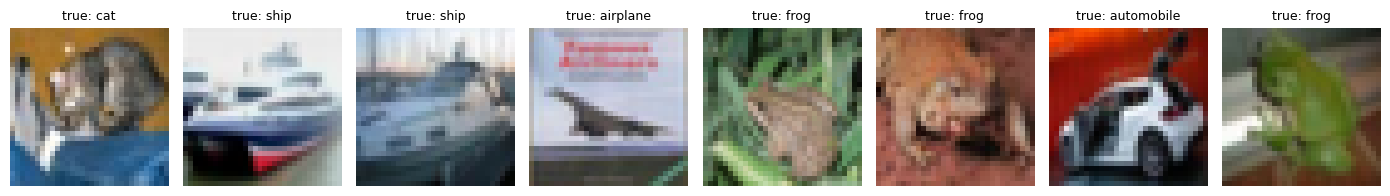

In [285]:
sample_images, sample_labels = next(iter(test_loader))
show_images(sample_images, sample_labels)

In [286]:
#Define Simple CNN
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 32x32 -> 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 16x16 -> 8x8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# use simple CNN defined here or pretrained

# model = SimpleCNN().to(device)
# print(model)

model = torch.hub.load(
    "chenyaofo/pytorch-cifar-models",
    "cifar10_resnet20",
    pretrained=True
)

model = model.to(device)
model.eval()


Using cache found in C:\Users\jonat/.cache\torch\hub\chenyaofo_pytorch-cifar-models_master


CifarResNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias

In [287]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [288]:
# saving/loading model
from pathlib import Path

CHECKPOINT_PATH = Path("simple_cnn_cifar10.pt")

def save_checkpoint(model, optimizer=None, history=None, path=CHECKPOINT_PATH):
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "history": history,
    }

    if optimizer is not None:
        checkpoint["optimizer_state_dict"] = optimizer.state_dict()

    torch.save(checkpoint, path)
    print(f"Saved checkpoint to {path}")

def load_checkpoint(model, optimizer=None, path=CHECKPOINT_PATH, device=device):
    checkpoint = torch.load(path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    if optimizer is not None and "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    history = checkpoint.get("history", None)

    print(f"Loaded checkpoint from {path}")
    return history

In [289]:
epochs = 7

history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": [],
}

if CHECKPOINT_PATH.exists():
    pass
    # history = load_checkpoint(model, optimizer, CHECKPOINT_PATH, device=device)
else:
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, train acc={train_acc:.4f} | "
            f"test loss={test_loss:.4f}, test acc={test_acc:.4f}"
        )

    save_checkpoint(model, optimizer, history, CHECKPOINT_PATH)

In [290]:
# plt.figure(figsize=(12, 4))

# plt.subplot(1, 2, 1)
# plt.plot(history["train_loss"], label="train")
# plt.plot(history["test_loss"], label="test")
# plt.title("Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Cross-entropy")
# plt.legend()

# plt.subplot(1, 2, 2)
# plt.plot(history["train_acc"], label="train")
# plt.plot(history["test_acc"], label="test")
# plt.title("Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.legend()

# plt.tight_layout()
# plt.show()

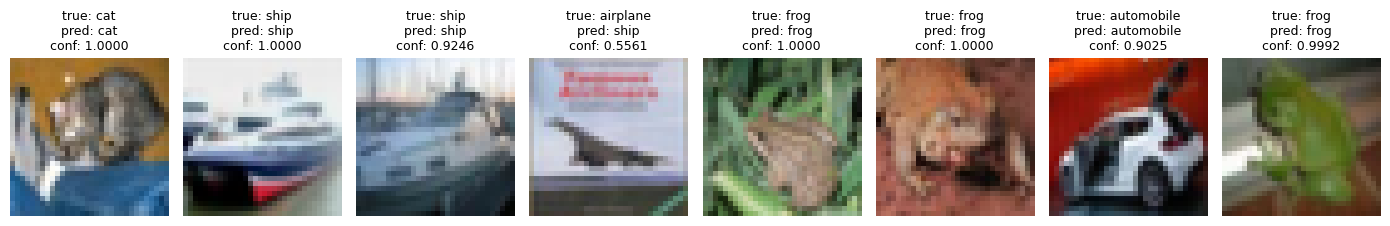

In [291]:
# Show Predictions
@torch.no_grad()
def predict_batch(model, images):
    model.eval()
    logits = model(images.to(device))
    probs = torch.softmax(logits, dim=1)
    confs, preds = probs.max(dim=1)
    return preds.cpu(), confs.cpu(), probs.cpu()

images, labels = next(iter(test_loader))
preds, confs, probs = predict_batch(model, images[:8])
show_images(images[:8], labels[:8], preds=preds, confs=confs.numpy())


True label: cat
Predicted label: cat
Prediction confidence: 1.0


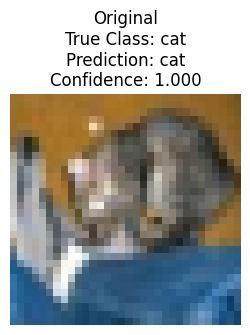

In [292]:
# work on one example
def get_single_example(loader, index_in_batch=0):
    images, labels = next(iter(loader))
    x = images[index_in_batch:index_in_batch+1].to(device)
    y = labels[index_in_batch:index_in_batch+1].to(device)
    return x, y

x0, y0 = get_single_example(test_loader, index_in_batch=0)

with torch.no_grad():
    logits0 = model(x0)
    probs0 = torch.softmax(logits0, dim=1)
    pred0 = probs0.argmax(dim=1)
    conf0 = probs0[0, pred0.item()].item()

print("True label:", classes[y0.item()])
print("Predicted label:", classes[pred0.item()])
print("Prediction confidence:", round(conf0, 4))

plt.figure(figsize=(3, 3))
plt.imshow(denormalize(x0[0]).cpu().permute(1, 2, 0).numpy())
plt.title(f"Original\nTrue Class: {classes[y0.item()]}\nPrediction: {classes[pred0.item()]}\nConfidence: {conf0:.3f}")
plt.axis("off")
plt.show()



Adversarial prediction: dog
Adversarial confidence: 0.5724


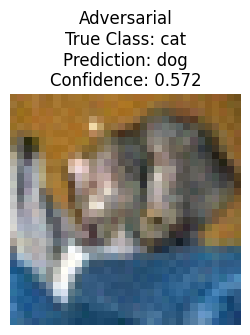

In [293]:
def fgsm_attack(model, x, y, epsilon=0.03):
    """
    x is normalized input.
    Returns:
        x_adv: adversarial example in normalized space
        grad: gradient wrt input
    """
    model.eval()

    x_adv = x.clone().detach().requires_grad_(True)
    logits = model(x_adv)
    loss = criterion(logits, y)

    model.zero_grad()
    loss.backward()

    grad = x_adv.grad.detach()
    x_adv = x_adv + epsilon * grad.sign()

    # Clip in pixel space, then renormalize
    x_pixel = denormalize(x_adv[0]).detach().clamp(0, 1)
    mean_t = torch.tensor(mean, device=device).view(3, 1, 1)
    std_t = torch.tensor(std, device=device).view(3, 1, 1)
    x_adv_norm = ((x_pixel - mean_t) / std_t).unsqueeze(0)

    return x_adv_norm.detach(), grad

epsilon = 0.07
x_adv, grad0 = fgsm_attack(model, x0, y0, epsilon=epsilon)

with torch.no_grad():
    probs_adv = torch.softmax(model(x_adv), dim=1)
    pred_adv = probs_adv.argmax(dim=1)
    conf_adv = probs_adv[0, pred_adv.item()].item()

print("Adversarial prediction:", classes[pred_adv.item()])
print("Adversarial confidence:", round(conf_adv, 4))

plt.figure(figsize=(3, 3))
plt.imshow(denormalize(x_adv[0]).cpu().permute(1, 2, 0).numpy())
plt.title(f"Adversarial\nTrue Class: {classes[y0.item()]}\nPrediction: {classes[pred_adv.item()]}\nConfidence: {conf_adv:.3f}")
plt.axis("off")
plt.show()


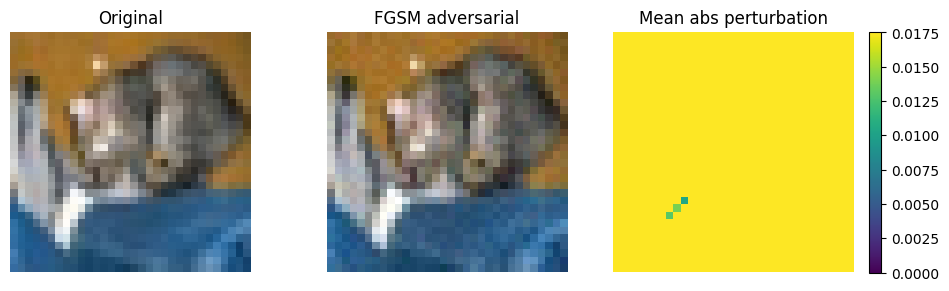

Original pred: cat (1.000)
Adversarial pred: dog (0.572)


In [294]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

axes[0].imshow(denormalize(x0[0]).cpu().permute(1, 2, 0).numpy())
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(denormalize(x_adv[0]).cpu().permute(1, 2, 0).numpy())
axes[1].set_title("FGSM adversarial")
axes[1].axis("off")

perturb = (denormalize(x_adv[0]) - denormalize(x0[0])).abs().mean(dim=0).cpu().numpy()
perturb_im = axes[2].imshow(perturb, vmin=0.0, vmax=np.max(perturb))
axes[2].set_title("Mean abs perturbation")
axes[2].axis("off")

clrbr = fig.colorbar(perturb_im, ax=axes[2])
plt.tight_layout()
plt.show()

print("Original pred:", classes[pred0.item()], f"({conf0:.3f})")
print("Adversarial pred:", classes[pred_adv.item()], f"({conf_adv:.3f})")


In [295]:
# initialize decision plane
def l2_normalize(t, eps=1e-12):
    return t / (t.norm() + eps)

def make_plane_directions(x0, grad):
    # direction 1: gradient direction
    d1 = l2_normalize(grad.detach().clone())

    # direction 2: random orthogonal direction
    d2 = torch.randn_like(x0)
    d2 = d2 - (d2.flatten() @ d1.flatten()) * d1 / (d1.flatten() @ d1.flatten() + 1e-12)
    d2 = l2_normalize(d2)

    return d1.detach(), d2.detach()

d1, d2 = make_plane_directions(x0, grad0)
print("||d1|| =", d1.norm().item())
print("||d2|| =", d2.norm().item())
print("dot(d1, d2) =", (d1.flatten() @ d2.flatten()).item())

||d1|| = 0.9999767541885376
||d2|| = 1.0
dot(d1, d2) = -3.259629011154175e-09


In [296]:
#generate plane
@torch.no_grad()
def project_point_along_plane(x0, d1, d2, a, b):
    x = x0 + a * d1 + b * d2

    # clip in pixel space, then renormalize
    x_pixel = denormalize(x[0]).clamp(0, 1)
    mean_t = torch.tensor(mean, device=device).view(3, 1, 1)
    std_t = torch.tensor(std, device=device).view(3, 1, 1)
    x = ((x_pixel - mean_t) / std_t).unsqueeze(0)
    return x

@torch.no_grad()
def evaluate_plane(model, x0, y0, d1, d2, grid_lim=2.0, steps=61):
    a_vals = torch.linspace(-grid_lim, grid_lim, steps, device=device)
    b_vals = torch.linspace(-grid_lim, grid_lim, steps, device=device)

    pred_grid = torch.empty((steps, steps), dtype=torch.long)
    maxconf_grid = torch.empty((steps, steps), dtype=torch.float32)
    trueconf_grid = torch.empty((steps, steps), dtype=torch.float32)

    model.eval()

    for i, a in enumerate(a_vals):
        batch = []
        for b in b_vals:
            batch.append(project_point_along_plane(x0, d1, d2, a.item(), b.item()))
        batch = torch.cat(batch, dim=0)

        logits = model(batch)
        probs = torch.softmax(logits, dim=1)

        maxconf, preds = probs.max(dim=1)
        trueconf = probs[:, y0.item()]

        pred_grid[i] = preds.cpu()
        maxconf_grid[i] = maxconf.cpu()
        trueconf_grid[i] = trueconf.cpu()

    return a_vals.cpu().numpy(), b_vals.cpu().numpy(), pred_grid.numpy(), maxconf_grid.numpy(), trueconf_grid.numpy()

grid_lim = 60.0
steps = 150

a_vals, b_vals, pred_grid, maxconf_grid, trueconf_grid = evaluate_plane(
    model, x0, y0, d1, d2, grid_lim=grid_lim, steps=steps
)

def plane_coordinates(x, x0, d1, d2):
    delta = (x - x0).detach()
    a = (delta.flatten() @ d1.flatten()).item()
    b = (delta.flatten() @ d2.flatten()).item()
    return a, b

a_adv, b_adv = plane_coordinates(x_adv, x0, d1, d2)
print("Adversarial point coordinates in the plane:", (a_adv, b_adv))

Adversarial point coordinates in the plane: (2.602850914001465, 0.06545716524124146)


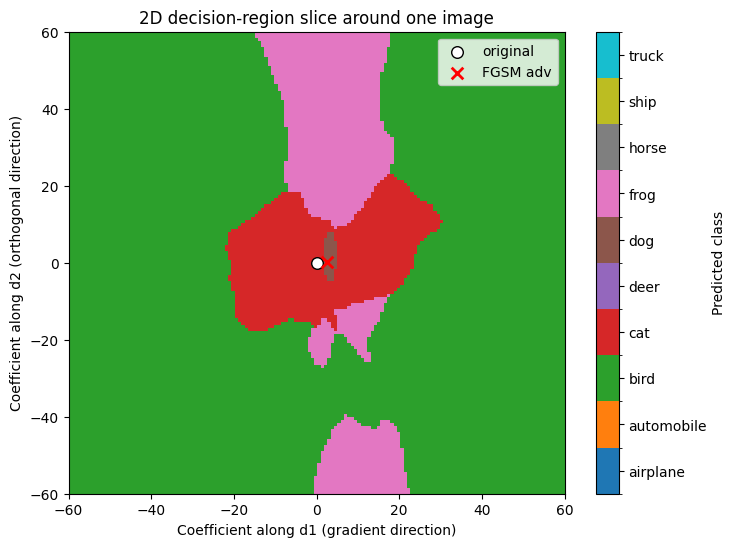

In [297]:
#setup class color map
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable

class_cmap = plt.get_cmap("tab10", len(classes))

class_norm = BoundaryNorm(np.arange(len(classes) + 1) - 0.5, len(classes))

class_mappable = ScalarMappable(cmap=class_cmap, norm=class_norm)
class_mappable.set_array([])

#2D decision region plot
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    pred_grid.T,
    origin="lower",
    extent=[a_vals.min(), a_vals.max(), b_vals.min(), b_vals.max()],
    aspect="auto",
    cmap=class_cmap,
    norm=class_norm
)

cbar = fig.colorbar(class_mappable, ax=ax)
cbar.set_ticks(range(len(classes)))
cbar.set_ticklabels(classes)
cbar.set_label("Predicted class")

ax.scatter(0, 0, c="white", edgecolors="black", s=70, marker="o", label="original")
ax.scatter(a_adv, b_adv, c="red", s=70, marker="x", linewidths=2, label="FGSM adv")

ax.set_xlabel("Coefficient along d1 (gradient direction)")
ax.set_ylabel("Coefficient along d2 (orthogonal direction)")
ax.set_title("2D decision-region slice around one image")
ax.legend()

plt.show()



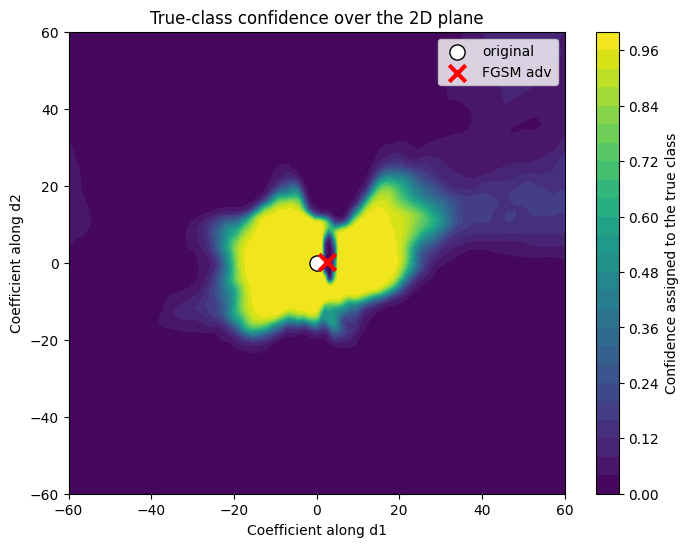

In [298]:
# 2d plot of True-class confidence
A, B = np.meshgrid(a_vals, b_vals, indexing="ij")

plt.figure(figsize=(8, 6))
cont = plt.contourf(A, B, trueconf_grid, levels=25)
plt.colorbar(cont, label="Confidence assigned to the true class")

plt.scatter(0, 0, c="white", edgecolors="black", s=120, marker="o", label="original")
plt.scatter(a_adv, b_adv, c="red", s=140, marker="x", linewidths=3, label="FGSM adv")

plt.xlabel("Coefficient along d1")
plt.ylabel("Coefficient along d2")
plt.title("True-class confidence over the 2D plane")
plt.legend()
plt.show()

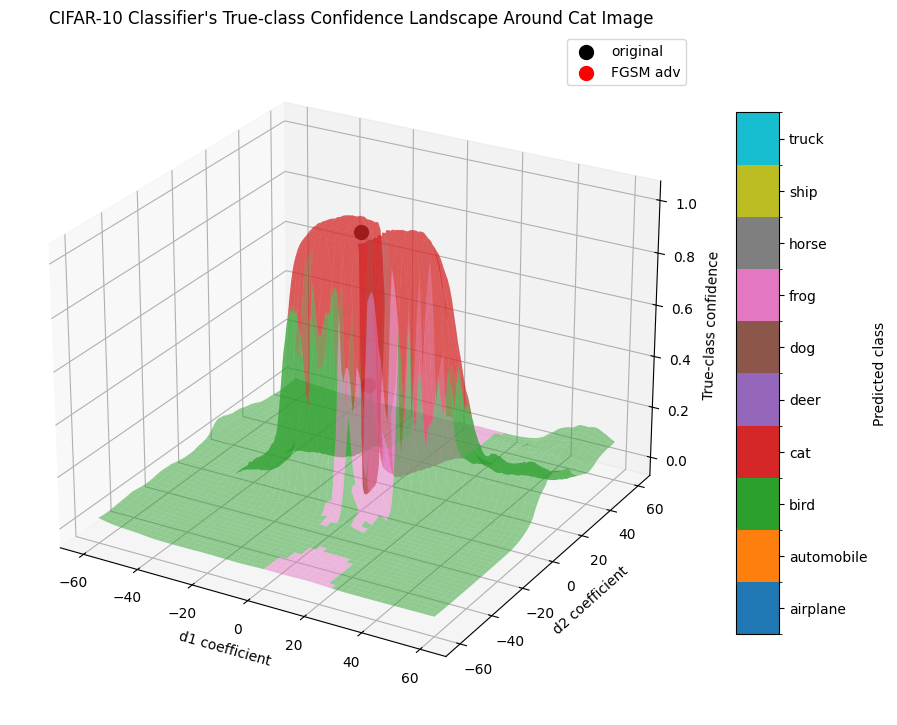

In [299]:
#3d confidence surface

@torch.no_grad()
def confidence_for_image(model, x, class_idx):
    model.eval()
    logits = model(x)
    probs = torch.softmax(logits, dim=1)
    return probs[0, class_idx].item()


fig = plt.figure(figsize=(18, 9))
ax1 = fig.add_subplot(121, projection="3d")
# ax2 = fig.add_subplot(122, projection="3d")

facecolors = class_cmap(class_norm(pred_grid))
for ax in [ax1]:
    surf = ax.plot_surface(
        A,
        B,
        trueconf_grid,
        facecolors=facecolors,
        linewidth=0,
        antialiased=True,
        alpha=0.5,
        shade=False
    )

    z0 = confidence_for_image(model, x0, y0.item())
    ai = np.argmin(np.abs(a_vals - a_adv))
    bi = np.argmin(np.abs(b_vals - b_adv))
    z_adv = confidence_for_image(model, x_adv, y0.item())

    ax.scatter([0], [0], [z0], c="black", s=100, alpha=1.0, depthshade=False, label="original")
    ax.scatter([a_adv], [b_adv], [z_adv], c="red", s=100, alpha=1.0, depthshade=False, label="FGSM adv")

    ax.set_xlabel("d1 coefficient")
    ax.set_ylabel("d2 coefficient")
    ax.set_zlabel("True-class confidence")
    ax.set_title("CIFAR-10 Classifier's True-class Confidence Landscape Around Cat Image")
    ax.legend()

cbar = fig.colorbar(class_mappable, ax=ax, shrink=0.6, aspect=12)
cbar.set_ticks(range(len(classes)))
cbar.set_ticklabels(classes)
cbar.set_label("Predicted class")

ax1.view_init(elev=25, azim=300)
# ax2.view_init(elev=25, azim=60)
plt.tight_layout()
plt.show()

In [300]:
mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)

def normalize_batch(x_pixel):
    """
    x_pixel: batch in [0, 1], shape (B, 3, 32, 32)
    returns normalized batch
    """
    return (x_pixel - mean_t) / std_t

def denormalize_batch(x_norm):
    """
    x_norm: normalized batch
    returns pixel-space batch clipped to [0, 1]
    """
    return (x_norm * std_t + mean_t).clamp(0, 1)

@torch.no_grad()
def predict_from_pixel(model, x_pixel):
    """
    x_pixel should be in [0, 1].
    """
    model.eval()
    logits = model(normalize_batch(x_pixel))
    return logits.argmax(dim=1)

def project_lp_ball(v, xi, p=np.inf):
    """
    Projects universal perturbation v onto an Lp ball of radius xi.
    For the demo, p=np.inf or p=2 are the useful choices.
    """
    if p == np.inf:
        return v.clamp(-xi, xi)

    elif p == 2:
        norm = v.flatten().norm(p=2)
        if norm > xi:
            v = v * (xi / norm)
        return v

    else:
        raise NotImplementedError("Only p=np.inf and p=2 are implemented.")

In [301]:
def deepfool_perturbation_pixel(
    model,
    x_pixel,
    original_pred,
    num_classes=10,
    max_iter=20,
    overshoot=0.02,
):
    """
    Approximate the minimal perturbation r such that:

        model(x_pixel + r) != original_pred

    x_pixel is in pixel space [0, 1].
    """

    model.eval()

    r_total = torch.zeros_like(x_pixel, device=device)

    for _ in range(max_iter):
        x_current = (x_pixel + r_total).clamp(0, 1).detach().requires_grad_(True)

        logits = model(normalize_batch(x_current))[0]
        current_pred = logits.argmax().item()

        if current_pred != original_pred:
            break

        logit_original = logits[original_pred]

        grad_original = torch.autograd.grad(
            logit_original,
            x_current,
            retain_graph=True,
            create_graph=False
        )[0]

        best_dist = float("inf")
        best_r = None

        for k in range(num_classes):
            if k == original_pred:
                continue

            logit_k = logits[k]

            grad_k = torch.autograd.grad(
                logit_k,
                x_current,
                retain_graph=True,
                create_graph=False
            )[0]

            # f = score_k - score_original
            f = logit_k - logit_original

            # w = grad(score_k - score_original)
            w = grad_k - grad_original

            w_norm_sq = torch.sum(w * w) + 1e-12

            # Distance to linearized boundary
            dist_k = torch.abs(f) / torch.sqrt(w_norm_sq)

            if dist_k.item() < best_dist:
                best_dist = dist_k.item()

                # Correct boundary-crossing direction
                best_r = (-f + 1e-4) * w / w_norm_sq

        if best_r is None:
            break

        r_total = r_total + best_r.detach()

    return (1 + overshoot) * r_total.detach()

In [302]:
@torch.no_grad()
def compute_fooling_rate(model, loader, v, max_samples=1000):
    """
    Fooling rate = fraction of images where k(x + v) != k(x).
    This follows the paper's use of classifier predictions, not ground-truth labels.
    """

    model.eval()

    fooled = 0
    total = 0

    for images, labels in loader:
        
        images = images.to(device)
        x_pixel = denormalize_batch(images)

        clean_preds = predict_from_pixel(model, x_pixel)
        adv_preds = predict_from_pixel(model, (x_pixel + v).clamp(0, 1))

        fooled += (adv_preds != clean_preds).sum().item()
        total += images.size(0)

        if total >= max_samples:
            break

    return fooled / total


def universal_adversarial_perturbation(
    model,
    loader,
    xi=8/255,
    p=np.inf,
    delta=0.2,
    max_passes=5,
    max_samples=1000,
    deepfool_max_iter=20,
):
    """
    Computes a universal perturbation v.

    xi: perturbation budget in pixel space.
        For CIFAR demos, 8/255 is a common L-infinity size.

    delta: desired error tolerance from the paper.
        The loop stops when fooling_rate >= 1 - delta.
        For delta=0.2, target fooling rate is 80%.

    returns:
        v: universal perturbation in pixel space, shape (1, 3, 32, 32)
        fooling_history: fooling rate after each pass
    """

    model.eval()

    v = torch.zeros((1, 3, 32, 32), device=device)
    fooling_history = []

    fooling_rate = compute_fooling_rate(model, loader, v, max_samples=max_samples)
    fooling_history.append(fooling_rate)

    print(f"Initial fooling rate: {fooling_rate:.4f}")

    pass_idx = 0
    best_v = v.clone()
    best_fooling_rate = fooling_rate
    while fooling_rate < 1 - delta and pass_idx < max_passes:

        updates = 0
        successful_deepfool_updates = 0
        avg_delta_norm = 0.0
        pass_idx += 1
        print(f"\nPass {pass_idx}/{max_passes}")

        seen = 0

        for images, labels in loader:
            images = images.to(device)
            x_pixels = denormalize_batch(images)

            for i in range(x_pixels.size(0)):
                x_pixel = x_pixels[i:i+1]

                with torch.no_grad():
                    original_pred = predict_from_pixel(model, x_pixel).item()
                    perturbed_pred = predict_from_pixel(model, (x_pixel + v).clamp(0, 1)).item()

                if perturbed_pred == original_pred:
                    updates += 1

                    delta_v_i = deepfool_perturbation_pixel(
                        model,
                        (x_pixel + v).clamp(0, 1),
                        original_pred,
                        num_classes=10,
                        max_iter=deepfool_max_iter,
                    )

                    delta_norm = delta_v_i.flatten().norm(p=2).item()
                    avg_delta_norm += delta_norm

                    old_v = v.clone()

                    v = project_lp_ball(v + delta_v_i, xi=xi, p=p).detach()

                    with torch.no_grad():
                        new_pred = predict_from_pixel(model, (x_pixel + v).clamp(0, 1)).item()

                    if new_pred != original_pred:
                        successful_deepfool_updates += 1

                seen += 1

                if seen >= max_samples:
                    break

            if seen >= max_samples:
                break

        fooling_rate = compute_fooling_rate(model, loader, v, max_samples=max_samples)
        fooling_history.append(fooling_rate)

        print(f"Fooling rate after pass {pass_idx}: {fooling_rate:.4f}")
        print(f"||v||_inf: {v.abs().max().item():.6f}")
        print(f"||v||_2: {v.flatten().norm(p=2).item():.6f}")
        print(f"Images needing update: {updates}")
        print(f"Successful post-update fools: {successful_deepfool_updates}")

        if updates > 0:
            print(f"Average delta_v_i L2 norm: {avg_delta_norm / updates:.6f}")
        if fooling_rate > best_fooling_rate:
            best_fooling_rate = fooling_rate
            best_v = v.clone()
            print(f"new best fooling rate {fooling_rate:.4f}")

    print(f"\nBest fooling rate: {best_fooling_rate:.4f}")
    return best_v.detach(), fooling_history

In [303]:
v_uap, uap_history = universal_adversarial_perturbation(
    model,
    train_loader,
    xi=8/255,
    p=np.inf,
    delta=0.2,          # target fooling rate (ex. 0.3 = 70%)
    max_passes=5,
    max_samples=500,   
    deepfool_max_iter=15,
)

Initial fooling rate: 0.0000

Pass 1/5
Fooling rate after pass 1: 0.6055
||v||_inf: 0.031373
||v||_2: 1.246789
Images needing update: 262
Successful post-update fools: 32
Average delta_v_i L2 norm: 0.087290
new best fooling rate 0.6055

Pass 2/5
Fooling rate after pass 2: 0.6504
||v||_inf: 0.031373
||v||_2: 1.261182
Images needing update: 164
Successful post-update fools: 0
Average delta_v_i L2 norm: 0.075041
new best fooling rate 0.6504

Pass 3/5
Fooling rate after pass 3: 0.6660
||v||_inf: 0.031373
||v||_2: 1.309519
Images needing update: 175
Successful post-update fools: 1
Average delta_v_i L2 norm: 0.071765
new best fooling rate 0.6660

Pass 4/5
Fooling rate after pass 4: 0.6699
||v||_inf: 0.031373
||v||_2: 1.331579
Images needing update: 173
Successful post-update fools: 2
Average delta_v_i L2 norm: 0.067093
new best fooling rate 0.6699

Pass 5/5
Fooling rate after pass 5: 0.6465
||v||_inf: 0.031373
||v||_2: 1.309525
Images needing update: 190
Successful post-update fools: 3
Avera

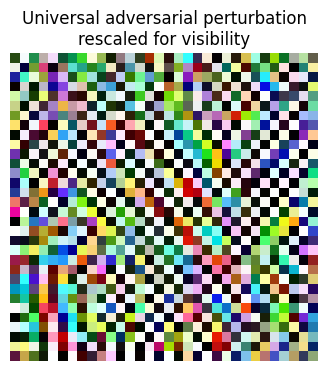

In [304]:
plt.figure(figsize=(4, 4))

# Rescale perturbation for visualization
v_vis = v_uap[0].detach().cpu()
v_vis = (v_vis - v_vis.min()) / (v_vis.max() - v_vis.min() + 1e-12)

plt.imshow(v_vis.permute(1, 2, 0).numpy())
plt.title("Universal adversarial perturbation\nrescaled for visibility")
plt.axis("off")
plt.show()

Clean predictions:


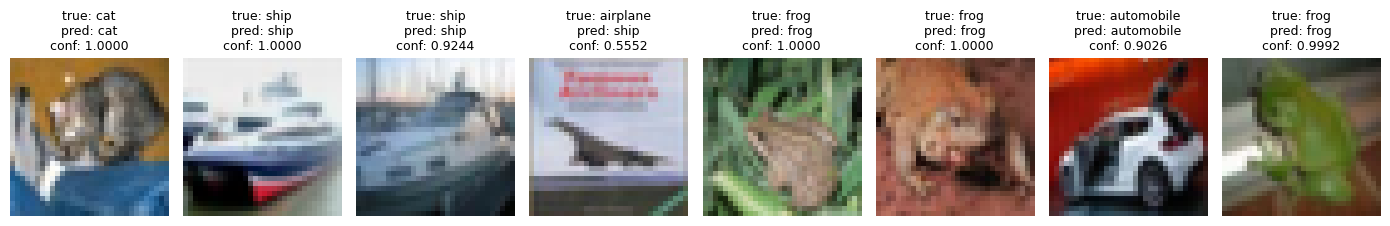

With universal perturbation:


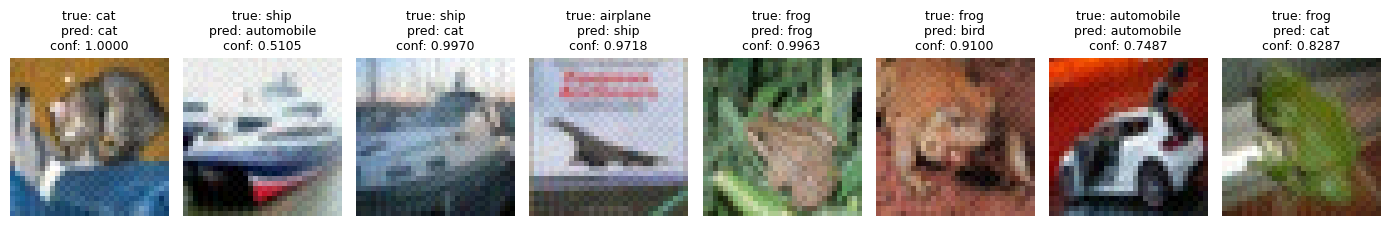

In [305]:
images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)

x_pixel = denormalize_batch(images)
x_adv_pixel = (x_pixel + v_uap).clamp(0, 1)

x_adv_norm = normalize_batch(x_adv_pixel)

with torch.no_grad():
    clean_logits = model(images)
    clean_probs = torch.softmax(clean_logits, dim=1)
    clean_confs, clean_preds = clean_probs.max(dim=1)

    adv_logits = model(x_adv_norm)
    adv_probs = torch.softmax(adv_logits, dim=1)
    adv_confs, adv_preds = adv_probs.max(dim=1)

print("Clean predictions:")
show_images(images[:8].cpu(), labels[:8].cpu(), preds=clean_preds[:8].cpu(), confs=clean_confs[:8].cpu().numpy())

print("With universal perturbation:")
show_images(x_adv_norm[:8].cpu(), labels[:8].cpu(), preds=adv_preds[:8].cpu(), confs=adv_confs[:8].cpu().numpy())

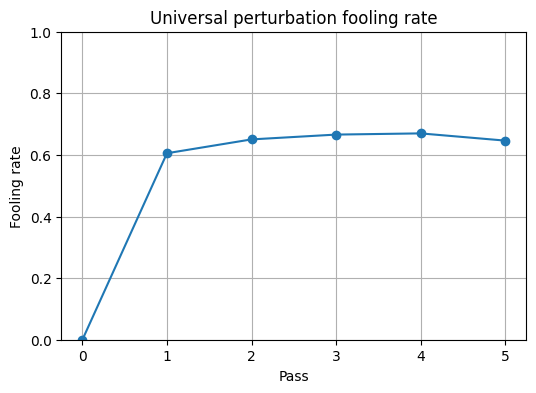

In [306]:
plt.figure(figsize=(6, 4))
plt.plot(uap_history, marker="o")
plt.xlabel("Pass")
plt.ylabel("Fooling rate")
plt.title("Universal perturbation fooling rate")
plt.ylim(0, 1)
plt.grid(True)
plt.show()